
# Week 3: Data Cleaning
## Airline Flight Delay Analysis

### Objective
To identify and address data-quality issues while preserving valid flight records.

### Dataset
- Records: 3,538,856
- Columns: 35
- Date range: January 1, 2024 – July 4, 2024

### Cleaning Tasks
1. Inspect missing values and their causes.
2. Validate cancelled and diverted flight records.
3. Convert columns to appropriate data types.
4. Check duplicate records and invalid values.
5. Investigate outliers using statistical methods and visualizations.
6. Save the cleaned dataset separately from the original.


In [1]:
import pandas as pd
import numpy as np
from pathlib import Path

file_path = Path(
    r"C:\Users\ashun\Downloads\flight_data_2024_final_cleaned.csv"
)

df = pd.read_csv(file_path, low_memory=False)

# Keep the original data unchanged
clean_df = df.copy()

print("Dataset loaded successfully!")
print("Original shape:", df.shape)
print("Cleaning copy shape:", clean_df.shape)

Dataset loaded successfully!
Original shape: (3538856, 35)
Cleaning copy shape: (3538856, 35)


In [2]:
# Compare missing values for cancelled, diverted, and other flights

print("Cancelled flights:", clean_df["cancelled"].sum())
print("Diverted flights:", clean_df["diverted"].sum())

print("\nMissing arrival delay by flight status:")
display(
    clean_df.groupby(["cancelled", "diverted"])["arr_delay"]
    .agg(
        total_flights="size",
        missing_arr_delay=lambda x: x.isna().sum()
    )
)

print("\nMissing departure delay by cancellation status:")
display(
    clean_df.groupby("cancelled")["dep_delay"]
    .agg(
        total_flights="size",
        missing_dep_delay=lambda x: x.isna().sum()
    )
)

Cancelled flights: 49107
Diverted flights: 9301

Missing arrival delay by flight status:


total_flights  missing_arr_delay
cancelled diverted                                  
0         0               3480448                  0
          1                  9301                  0
1         0                 49107              49107


Missing departure delay by cancellation status:


,total_flights,missing_dep_delay
cancelled,,
0,3489749,0
1,49107,47390


In [3]:
# Investigate missing departure data
columns_to_check = [
    "dep_time",
    "dep_delay",
    "taxi_out",
    "wheels_off",
    "arr_time",
    "arr_delay",
    "cancellation_code"
]

display(
    clean_df.groupby("cancelled")[columns_to_check]
    .agg(lambda column: column.isna().sum())
    .rename(index={0: "Not Cancelled", 1: "Cancelled"})
)

,dep_time,dep_delay,taxi_out,wheels_off,arr_time,arr_delay,cancellation_code
cancelled,,,,,,,
Not Cancelled,0,0,0,0,0,0,3489749
Cancelled,47192,47390,48797,48797,49107,49107,0


In [4]:
# Cancellation-code consistency check

print("Cancelled flights by cancellation code:")
display(
    clean_df.loc[clean_df["cancelled"] == 1, "cancellation_code"]
    .value_counts(dropna=False)
)

print("\nCancellation-code values in non-cancelled flights:")
display(
    clean_df.loc[clean_df["cancelled"] == 0, "cancellation_code"]
    .value_counts(dropna=False)
)

Cancelled flights by cancellation code:


cancellation_code
B    29810
A    14230
C     5065
D        2
Name: count, dtype: int64


Cancellation-code values in non-cancelled flights:


cancellation_code
NaN    3489749
Name: count, dtype: int64

In [5]:
# Check repeated flight identifiers
flight_keys = [
    "fl_date",
    "op_unique_carrier",
    "op_carrier_fl_num",
    "origin",
    "dest"
]

print("Repeated flight-key rows:")
print(clean_df.duplicated(subset=flight_keys, keep=False).sum())

print("\nNumber of repeated flight-key combinations:")
print(
    clean_df.loc[
        clean_df.duplicated(subset=flight_keys, keep=False),
        flight_keys
    ].drop_duplicates().shape[0]
)

Repeated flight-key rows:
0

Number of repeated flight-key combinations:
0



## Week 3: Initial Data Cleaning Audit

### Findings
- Exact duplicate rows: 0
- Repeated flight-key combinations: 0
- Cancelled flights: 49,107
- Diverted flights: 9,301
- Missing arrival delays: 49,107, all associated with cancelled flights.
- Missing cancellation codes: 3,489,749, matching non-cancelled flights.
- Negative distances: 0
- Negative scheduled elapsed times: 0

### Cleaning Decisions
1. Preserve valid flight records; do not remove rows solely because values are missing.
2. Retain missing cancellation codes for non-cancelled flights.
3. Investigate missing operational times in cancelled flights before imputation.
4. Convert `fl_date` to datetime in the analysis copy.
5. Examine delay distributions and outliers before deciding on treatment.

### Limitation
The dataset covers January 1 through July 4, 2024, not the full year.



dep_delay
Lower bound: -30.0
Upper bound: 34.0
Outlier count: 445649

arr_delay
Lower bound: -54.0
Upper bound: 50.0
Outlier count: 320047


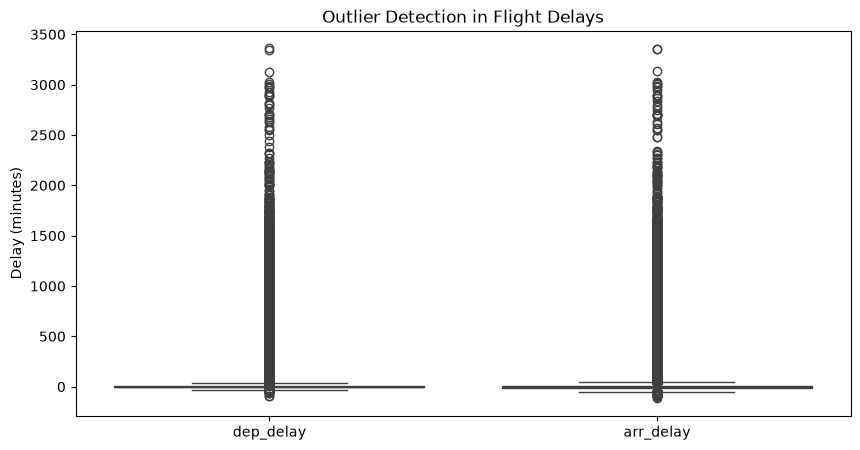

In [6]:

# Week 3: Outlier Detection using IQR

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

delay_columns = ["dep_delay", "arr_delay"]

for col in delay_columns:
    values = clean_df[col].dropna()

    Q1 = values.quantile(0.25)
    Q3 = values.quantile(0.75)
    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    outliers = ((values < lower) | (values > upper)).sum()

    print(f"\n{col}")
    print("Lower bound:", round(lower, 2))
    print("Upper bound:", round(upper, 2))
    print("Outlier count:", outliers)

# Visualize delay distributions with boxplots
plt.figure(figsize=(10, 5))
sns.boxplot(data=clean_df[delay_columns])
plt.title("Outlier Detection in Flight Delays")
plt.ylabel("Delay (minutes)")
plt.show()


### Outlier Analysis Findings

The IQR method identified 445,649 outliers in departure delays and 320,047 in arrival delays. The boxplots show strongly right-skewed distributions with several extreme delay values. These outliers may represent genuine flight disruptions, so they were retained rather than automatically removed.